# IA y empleo en Perú: ENAHO 2024

Versión anual final del cruce entre ENAHO y el índice ocupacional de exposición a IA. Este cuaderno replica la lógica del HTML maestro, pero concentrada en un solo año y con salidas desagregadas para auditoría y revisión.

## Alcance

- Año analizado: **2024**
- Base laboral: **ENAHO anual, ocupados**
- Índice: **Claude Sonnet 4-6 / abril 2026**
- Clasificación ocupacional: **CNO-2015 a 4 dígitos**
- Este cuaderno está pensado como versión final reproducible del corte anual, alineada con el HTML maestro.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from IPython.display import HTML, display

try:
    import plotly.express as px
    import plotly.graph_objects as go
    HAS_PLOTLY = True
except ModuleNotFoundError:
    px = None
    go = None
    HAS_PLOTLY = False

PROJECT_ROOT = Path(r"C:\Users\VALENTINALINARES\OneDrive - Universidad del Pacífico\Desktop\up cowork\ENAHO 2026\Proyecto_IA_Empleo_2026")
WORKSPACE_ROOT = Path(r"C:\Users\VALENTINALINARES\OneDrive - Universidad del Pacífico\Desktop\up cowork\ENAHO 2026")
BASE_CSV_PATH = Path(r"C:\Users\VALENTINALINARES\OneDrive - Universidad del Pacífico\Desktop\up cowork\ENAHO 2026\Proyecto_IA_Empleo_2026\data\intermediate\enaho_complete_years\ENAHO_complete_2024.csv")
INDEX_PATH = Path(r"C:\Users\VALENTINALINARES\OneDrive - Universidad del Pacífico\Desktop\up cowork\ENAHO 2026\abril2026\anthropic-claude-sonnet-4-6_exposure_index.xlsx")
REPORT_PATH = Path(r"C:\Users\VALENTINALINARES\OneDrive - Universidad del Pacífico\Desktop\up cowork\ENAHO 2026\Proyecto_IA_Empleo_2026\outputs\enaho_exposure_2024\enaho_exposure_2024_occupation_report.xlsx")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = Path(r"C:\Users\VALENTINALINARES\OneDrive - Universidad del Pacífico\Desktop\up cowork\ENAHO 2026\Proyecto_IA_Empleo_2026\outputs\enaho_exposure_2024")
OUTPUT_TABLES = OUTPUT_DIR / "annual_tables"
OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)
ANALYSIS_YEAR = 2024

PROFILE_SHEETS = [
    "sexo",
    "educacion",
    "categoria",
    "categoria_agregada",
    "grupo_edad",
    "formalidad_contrato",
    "formalidad_tamano",
    "rama",
    "estrato",
]
PERSONA_REGIONS = [(15, "Lima"), (4, "Arequipa"), (13, "La Libertad"), (7, "Callao")]
DEPT_NAMES = {
    1: "Amazonas",
    2: "Ancash",
    3: "Apurímac",
    4: "Arequipa",
    5: "Ayacucho",
    6: "Cajamarca",
    7: "Callao",
    8: "Cusco",
    9: "Huancavelica",
    10: "Huánuco",
    11: "Ica",
    12: "Junín",
    13: "La Libertad",
    14: "Lambayeque",
    15: "Lima",
    16: "Loreto",
    17: "Madre de Dios",
    18: "Moquegua",
    19: "Pasco",
    20: "Piura",
    21: "Puno",
    22: "San Martín",
    23: "Tacna",
    24: "Tumbes",
    25: "Ucayali",
}
CAT_MAP = {
    1: "Empleador/a",
    2: "Independiente",
    3: "Empleado/a",
    4: "Obrero/a",
    5: "Familiar no remunerado/a",
    6: "Trab. del hogar",
    7: "Otro",
}
EDU_MAP = {
    1: "sin nivel",
    2: "educación inicial",
    3: "primaria incompleta",
    4: "primaria completa",
    5: "secundaria incompleta",
    6: "secundaria completa",
    7: "superior no universitaria incompleta",
    8: "superior no universitaria completa",
    9: "superior universitaria incompleta",
    10: "superior universitaria completa",
    11: "maestría/doctorado",
    12: "básica especial",
}
COLORS = {
    "accent": "#c25b2a",
    "accent2": "#2563eb",
    "accent3": "#059669",
    "yellow": "#d97706",
    "text": "#1a1a1a",
    "muted": "#6b7280",
    "border": "#e5e7eb",
    "bg": "#f8f8f6",
    "card": "#ffffff",
}

pd.set_option("display.max_columns", 160)
pd.set_option("display.max_rows", 120)
if HAS_PLOTLY:
    px.defaults.template = "plotly_white"

CSS = f"""
<style>
body {{ background:{COLORS["bg"]}; }}
.audit-grid {{ display:grid; grid-template-columns:repeat(auto-fit,minmax(180px,1fr)); gap:12px; margin:8px 0 20px 0; }}
.audit-card {{ background:{COLORS["card"]}; border:1px solid {COLORS["border"]}; border-radius:14px; padding:14px 16px; }}
.audit-card .eyebrow {{ font-size:11px; text-transform:uppercase; letter-spacing:.08em; color:{COLORS["muted"]}; }}
.audit-card .value {{ font-size:30px; font-weight:700; color:{COLORS["accent"]}; margin-top:4px; }}
.audit-card .sub {{ font-size:12px; color:{COLORS["muted"]}; margin-top:3px; }}
.audit-note {{ background:#fffbf5; border-left:4px solid {COLORS["yellow"]}; border-radius:0 10px 10px 0; padding:12px 16px; margin:14px 0; color:#78350f; }}
.audit-note.blue {{ background:#eff6ff; border-left-color:{COLORS["accent2"]}; color:#1e3a8a; }}
.audit-note.green {{ background:#f0fdf4; border-left-color:{COLORS["accent3"]}; color:#14532d; }}
.mini-tag {{ display:inline-block; padding:2px 8px; border-radius:999px; background:#f3f4f6; color:{COLORS["muted"]}; font-size:11px; margin-right:6px; }}
</style>
"""
display(HTML(CSS))

def safe_zfill(series):
    return pd.to_numeric(series, errors="coerce").astype("Int64").astype("string").str.zfill(4)

def weighted_mean(values, weights):
    v = pd.to_numeric(values, errors="coerce")
    w = pd.to_numeric(weights, errors="coerce")
    mask = v.notna() & w.notna() & (w > 0)
    if not mask.any():
        return np.nan
    return float(np.average(v[mask], weights=w[mask]))

def weighted_share(mask, weights):
    return weighted_mean(pd.Series(mask).astype(float), weights)

def weighted_median(values, weights):
    v = pd.to_numeric(values, errors="coerce")
    w = pd.to_numeric(weights, errors="coerce")
    mask = v.notna() & w.notna() & (w > 0)
    if not mask.any():
        return np.nan
    ordered = pd.DataFrame({"value": v[mask], "weight": w[mask]}).sort_values("value")
    cutoff = ordered["weight"].sum() / 2
    return float(ordered.loc[ordered["weight"].cumsum() >= cutoff, "value"].iloc[0])

def fmt_pct(value, digits=1):
    if pd.isna(value):
        return "N/D"
    return f"{value * 100:.{digits}f}%"

def fmt_num(value):
    if pd.isna(value):
        return "N/D"
    return f"{value:,.0f}"

def fmt_sol(value):
    if pd.isna(value):
        return "N/D"
    return f"S/ {value:,.0f}"

def render_cards(cards):
    html = ['<div class="audit-grid">']
    for card in cards:
        html.append(
            "<div class='audit-card'>"
            f"<div class='eyebrow'>{card['label']}</div>"
            f"<div class='value'>{card['value']}</div>"
            f"<div class='sub'>{card['sub']}</div>"
            "</div>"
        )
    html.append("</div>")
    display(HTML("".join(html)))

def render_note(text, tone="amber"):
    klass = "audit-note"
    if tone == "blue":
        klass += " blue"
    elif tone == "green":
        klass += " green"
    display(HTML(f"<div class='{klass}'>{text}</div>"))

def show_plotly(fig, include_js=False):
    if HAS_PLOTLY and fig is not None:
        display(HTML(fig.to_html(full_html=False, include_plotlyjs="cdn" if include_js else False)))

In [2]:
report_xl = pd.ExcelFile(REPORT_PATH)
report = {sheet: report_xl.parse(sheet) for sheet in report_xl.sheet_names}
occupation_summary = report["occupation_summary"].copy()
occupation_summary["code"] = occupation_summary["code"].astype(str).str.zfill(4)
occupation_summary = occupation_summary.sort_values("weighted_population", ascending=False).reset_index(drop=True)
coverage = report["coverage"].iloc[0].to_dict()
profiles = {sheet: report[sheet].copy() for sheet in PROFILE_SHEETS if sheet in report}

top_occ = (
    occupation_summary[occupation_summary["weighted_population"] > 50000]
    .nlargest(20, "mean_exposure_score")
    .copy()
)
bubble_df = occupation_summary[occupation_summary["weighted_population"] >= 80000].copy()
bubble_df["workers_millions"] = bubble_df["weighted_population"] / 1_000_000
bubble_df["women_pct"] = bubble_df["share_women"] * 100

comparison_rows = []
for sheet_name, df in profiles.items():
    clean = df.dropna(subset=["mean_exposure_score"]).sort_values("mean_exposure_score", ascending=False).copy()
    if clean.empty:
        continue
    top_row = clean.iloc[0]
    bottom_row = clean.iloc[-1]
    comparison_rows.append(
        {
            "dimension": sheet_name,
            "top_group": str(top_row["group"]),
            "top_exposure": float(top_row["mean_exposure_score"]),
            "top_share": float(top_row["population_share"]),
            "bottom_group": str(bottom_row["group"]),
            "bottom_exposure": float(bottom_row["mean_exposure_score"]),
            "bottom_share": float(bottom_row["population_share"]),
            "gap_exposure": float(top_row["mean_exposure_score"] - bottom_row["mean_exposure_score"]),
        }
    )
comparison_df = pd.DataFrame(comparison_rows).sort_values("gap_exposure", ascending=False).reset_index(drop=True)

idx = pd.read_excel(INDEX_PATH)
idx["code"] = safe_zfill(idx["code"])
idx = idx[
    [
        "code",
        "occupation_group",
        "mean_exposure_score",
        "median_exposure_score",
        "%_alta_exposicion",
        "%_media_alta_exp",
        "%_sustitucion",
        "%_aumento",
    ]
].copy()

base = pd.read_csv(BASE_CSV_PATH, low_memory=False)
if "year" in base.columns:
    base = base[base["year"] == ANALYSIS_YEAR].copy()
if "ocu500" in base.columns:
    base["ocu500"] = pd.to_numeric(base["ocu500"], errors="coerce")
    base = base[base["ocu500"] == 1].copy()
base["factor"] = pd.to_numeric(base["factor"], errors="coerce").fillna(0)
base = base[base["factor"] > 0].copy()
base["occupation_code_4d"] = safe_zfill(base["ocupación del trabajador"])
base["age"] = pd.to_numeric(base["edad del trabajador"], errors="coerce")
base_merged = base.merge(idx, how="left", left_on="occupation_code_4d", right_on="code")
matched_base = base_merged[base_merged["mean_exposure_score"].notna()].copy()

enaho_micro = pd.read_csv(PROCESSED_DIR / "enaho_persona_anual_2019_2024.csv.gz")
enaho_micro = enaho_micro[enaho_micro["year"] == ANALYSIS_YEAR].copy()
enaho_micro["weight"] = pd.to_numeric(enaho_micro["weight"], errors="coerce")
enaho_micro["labor_income_monthly"] = pd.to_numeric(enaho_micro["labor_income_monthly"], errors="coerce")
enaho_micro["age"] = pd.to_numeric(enaho_micro["age"], errors="coerce")
enaho_micro["is_urban"] = pd.to_numeric(enaho_micro["is_urban"], errors="coerce")
enaho_micro = enaho_micro[enaho_micro["weight"] > 0].copy()
enaho_micro["occupation_code_4d"] = safe_zfill(enaho_micro["occupation_code_4d"])
enaho_micro["education_label"] = pd.to_numeric(enaho_micro["education_code"], errors="coerce").map(EDU_MAP)
enaho_micro["category_label"] = pd.to_numeric(enaho_micro["occupational_category_code"], errors="coerce").map(CAT_MAP).fillna("Otro")
enaho_micro["region_name"] = pd.to_numeric(enaho_micro["region_code"], errors="coerce").map(DEPT_NAMES)
enaho_micro = enaho_micro.merge(idx, how="inner", left_on="occupation_code_4d", right_on="code")

q25 = enaho_micro["mean_exposure_score"].quantile(0.25)
q75 = enaho_micro["mean_exposure_score"].quantile(0.75)
persona_q1 = enaho_micro[enaho_micro["mean_exposure_score"] <= q25].copy()
persona_q4 = enaho_micro[enaho_micro["mean_exposure_score"] >= q75].copy()

resumen = pd.read_csv(PROCESSED_DIR / "resumen_ocupacion_anio.csv.gz")
resumen["occupation_code_4d"] = safe_zfill(resumen["occupation_code_4d"])
income_df = resumen[
    (resumen["source"] == "ENAHO") &
    (resumen["year"] == ANALYSIS_YEAR) &
    (resumen["weighted_population"] > 50000) &
    (resumen["income_monthly_weighted_mean"].notna())
].copy()
income_df = income_df.merge(
    idx[["code", "occupation_group", "mean_exposure_score", "%_alta_exposicion"]],
    how="inner",
    left_on="occupation_code_4d",
    right_on="code",
)
income_df["income_gap_vs_median"] = income_df["income_monthly_weighted_mean"] - income_df["income_monthly_median_weighted"]
income_corr = income_df["mean_exposure_score"].corr(income_df["income_monthly_weighted_mean"]) if len(income_df) >= 3 else np.nan

epen = pd.read_csv(PROCESSED_DIR / "epen_persona_departamentos_anual_2022_2025.csv.gz")
epen["occupation_code_4d"] = safe_zfill(epen["occupation_code_4d"])
epen["weight"] = pd.to_numeric(epen["weight"], errors="coerce")
epen["labor_income_monthly"] = pd.to_numeric(epen["labor_income_monthly"], errors="coerce")
epen = epen[(epen["year"] == ANALYSIS_YEAR) & (epen["weight"] > 0)].copy()
if not epen.empty:
    epen = epen.merge(
        idx[["code", "occupation_group", "mean_exposure_score", "%_alta_exposicion", "%_aumento", "%_sustitucion"]],
        how="inner",
        left_on="occupation_code_4d",
        right_on="code",
    )
    regional_df = (
        epen.groupby("region_code", dropna=False)
        .apply(
            lambda g: pd.Series(
                {
                    "region_name": DEPT_NAMES.get(int(g.name), f"Región {int(g.name)}") if pd.notna(g.name) else "N/D",
                    "workers": g["weight"].sum(),
                    "mean_exposure": weighted_mean(g["mean_exposure_score"], g["weight"]),
                    "pct_alta": weighted_mean(g["%_alta_exposicion"], g["weight"]),
                    "pct_aumento": weighted_mean(g["%_aumento"], g["weight"]),
                    "pct_sustitucion": weighted_mean(g["%_sustitucion"], g["weight"]),
                    "income_mean": weighted_mean(g["labor_income_monthly"], g["weight"]),
                }
            ),
            include_groups=False,
        )
        .reset_index()
        .sort_values("mean_exposure", ascending=False)
        .reset_index(drop=True)
    )
    regional_top_occ = (
        epen.groupby(["region_code", "occupation_code_4d", "occupation_group"], dropna=False)
        .apply(
            lambda g: pd.Series(
                {
                    "workers": g["weight"].sum(),
                    "mean_exposure": weighted_mean(g["mean_exposure_score"], g["weight"]),
                }
            ),
            include_groups=False,
        )
        .reset_index()
    )
    regional_top_occ = regional_top_occ[regional_top_occ["workers"] > 10000].copy()
else:
    regional_df = pd.DataFrame(columns=["region_code", "region_name", "workers", "mean_exposure", "pct_alta", "pct_aumento", "pct_sustitucion", "income_mean"])
    regional_top_occ = pd.DataFrame(columns=["region_code", "occupation_code_4d", "occupation_group", "workers", "mean_exposure"])

crosswalk = pd.read_csv(PROCESSED_DIR / "ocupacion_crosswalk_4d.csv")
crosswalk["occupation_code_4d"] = crosswalk["occupation_code_4d"].astype(str).str.zfill(4)

unmatched_occ = (
    base_merged[base_merged["mean_exposure_score"].isna() & base_merged["occupation_code_4d"].notna()]
    .groupby("occupation_code_4d", dropna=False)
    .agg(weighted_population=("factor", "sum"))
    .reset_index()
    .sort_values("weighted_population", ascending=False)
)
unmatched_occ = unmatched_occ.merge(crosswalk[["occupation_code_4d", "occupation_name_cno"]], how="left", on="occupation_code_4d")
unmatched_occ["reason"] = np.where(unmatched_occ["occupation_name_cno"].notna(), "Sin score en índice IA", "Sin nombre en crosswalk")

income_outliers = enaho_micro[enaho_micro["labor_income_monthly"].notna()].copy()
outliers_over_20k = int((income_outliers["labor_income_monthly"] > 20000).sum())
outliers_over_50k = int((income_outliers["labor_income_monthly"] > 50000).sum())

audit_summary = {
    "report_rows": int(len(base)),
    "report_weight_total": float(base["factor"].sum()),
    "coverage_weighted": float(coverage["cobertura_ponderada"]),
    "covered_workers": float(coverage["peso_con_indice"]),
    "mean_exposure": float(coverage["media_exposicion_ponderada"]),
    "pct_alta": float(coverage["media_pct_alta_ponderada"]),
    "pct_sustitucion": float(coverage["media_pct_sustitucion_ponderada"]),
    "pct_aumento": float(coverage["media_pct_aumento_ponderada"]),
    "matched_occupations": int(coverage["ocupaciones_emparejadas"]),
    "observed_occupations": int(coverage["ocupaciones_observadas"]),
    "unmatched_occupations": int(len(unmatched_occ)),
    "income_outliers_over_20k": outliers_over_20k,
    "income_outliers_over_50k": outliers_over_50k,
}

print(f"Año analizado: {ANALYSIS_YEAR}")
print(f"Ocupaciones en reporte anual: {len(occupation_summary)}")
print(f"Cobertura ponderada: {coverage['cobertura_ponderada']:.4f}")
print(f"Ocupaciones sin score IA: {len(unmatched_occ)}")

Año analizado: 2024
Ocupaciones en reporte anual: 379
Cobertura ponderada: 0.9687
Ocupaciones sin score IA: 22


## Panorama anual

In [3]:
render_cards(
    [
        {
            "label": "Cobertura del índice",
            "value": fmt_pct(coverage["cobertura_ponderada"]),
            "sub": f"{fmt_num(coverage['peso_con_indice'])} ocupados ponderados con match",
        },
        {
            "label": "Exposición media",
            "value": fmt_pct(coverage["media_exposicion_ponderada"]),
            "sub": "Promedio ponderado del score ocupacional",
        },
        {
            "label": "Alta exposición",
            "value": fmt_pct(coverage["media_pct_alta_ponderada"]),
            "sub": "Participación ponderada de tareas altamente expuestas",
        },
        {
            "label": "Augmentation / sustitución",
            "value": f"{fmt_pct(coverage['media_pct_aumento_ponderada'])} / {fmt_pct(coverage['media_pct_sustitucion_ponderada'])}",
            "sub": "Promedios ponderados del índice ocupacional",
        },
    ]
)

render_note(
    "Este cuaderno usa exactamente el reporte anual ya consolidado en Excel y lo cruza con los microdatos armonizados para abrir cada componente por año. "
    "La redacción y las salidas corresponden a una versión final, trazable y replicable.",
    tone="green",
)

pd.DataFrame([coverage]).T.rename(columns={0: "valor"})

,valor
filas_totales,5.857900e+04
filas_con_ocupacion,5.857900e+04
filas_con_indice,5.707800e+04
peso_total,1.822932e+07
peso_con_ocupacion,1.822932e+07
peso_con_indice,1.765796e+07
cobertura_ponderada,9.686569e-01
cobertura_condicional_ocupacion,9.686569e-01
ocupaciones_observadas,4.010000e+02
ocupaciones_emparejadas,3.790000e+02


## 1. Ocupaciones más expuestas

In [4]:
display(
    top_occ[
        [
            "code",
            "occupation_group",
            "weighted_population",
            "mean_exposure_score",
            "pct_alta_exposicion",
            "pct_aumento",
            "share_women",
        ]
    ].rename(
        columns={
            "code": "cno_4d",
            "occupation_group": "ocupacion",
            "weighted_population": "trabajadores",
            "mean_exposure_score": "exposicion_media",
            "pct_alta_exposicion": "pct_alta_exposicion",
            "pct_aumento": "pct_aumento",
            "share_women": "pct_mujeres",
        }
    )
)

if HAS_PLOTLY:
    fig = px.bar(
        top_occ.sort_values("mean_exposure_score"),
        x="mean_exposure_score",
        y="occupation_group",
        orientation="h",
        color="weighted_population",
        color_continuous_scale=["#fde68a", "#c25b2a"],
        hover_data={
            "code": True,
            "weighted_population": ":,.0f",
            "pct_alta_exposicion": ":.1%",
            "pct_aumento": ":.1%",
            "share_women": ":.1%",
        },
        labels={
            "mean_exposure_score": "Exposición media",
            "occupation_group": "Ocupación",
            "weighted_population": "Trabajadores",
        },
    )
    fig.update_layout(
        title=f"Top 20 ocupaciones con mayor exposición media ({ANALYSIS_YEAR})",
        height=720,
        coloraxis_colorbar_title="Trabajadores",
        margin=dict(l=10, r=10, t=60, b=20),
    )
    show_plotly(fig, include_js=True)
else:
    ordered = top_occ.sort_values("mean_exposure_score")
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(ordered["occupation_group"], ordered["mean_exposure_score"], color=COLORS["accent"])
    ax.set_xlabel("Exposición media")
    ax.set_ylabel("")
    ax.set_title(f"Top 20 ocupaciones con mayor exposición media ({ANALYSIS_YEAR})")
    plt.tight_layout()
    plt.show()

,cno_4d,ocupacion,trabajadores,exposicion_media,pct_alta_exposicion,pct_aumento,pct_mujeres
63,4312,"Empleados de servicios estadísticos, financier...",5.796697e+04,0.7775,1.0000,0.5000,0.529946
49,4222,Empleados de centros de llamadas,7.759956e+04,0.7025,1.0000,1.0000,0.575057
64,5243,Vendedores por teléfono,5.646361e+04,0.6808,1.0000,1.0000,0.746427
12,3314,Técnicos en administración,2.601597e+05,0.6725,1.0000,0.7500,0.390139
38,2411,Contadores,8.726444e+04,0.6713,1.0000,1.0000,0.533623
20,4110,Jefes de empleados administrativos,1.550957e+05,0.6333,0.6667,1.0000,0.407188
61,4417,"Auxiliares en la administración, contabilidad,...",6.074048e+04,0.6007,0.6000,1.0000,0.532831
2,5212,Vendedores minoristas en tiendas y establecimi...,1.326993e+06,0.5993,0.6000,1.0000,0.743168
52,2359,Otros profesionales de la enseñanza,7.354687e+04,0.5800,0.5000,0.8333,0.429587
54,4120,Secretarios,6.679462e+04,0.5467,0.2000,0.6000,0.991740


## 2. Mapa ocupacional

Se replica el producto principal del HTML para el año seleccionado: exposición media por ocupación, tamaño del empleo y composición por sexo.

In [5]:
render_note(
    "El gráfico feo de ocupaciones contra sustitución se eliminó. En la versión final, el mapa ocupacional replica el producto del HTML maestro: "
    "exposición media, tamaño del empleo y composición por sexo.",
    tone="blue",
)

if HAS_PLOTLY:
    fig = px.scatter(
        bubble_df,
        x="mean_exposure_score",
        y="weighted_population",
        size="weighted_population",
        color="share_women",
        color_continuous_scale=["#2563eb", "#f59e0b", "#c25b2a"],
        hover_name="occupation_group",
        hover_data={
            "code": True,
            "weighted_population": ":,.0f",
            "pct_alta_exposicion": ":.1%",
            "pct_aumento": ":.1%",
            "share_women": ":.1%",
            "mean_age": ":.1f",
        },
        labels={
            "mean_exposure_score": "Exposición media",
            "weighted_population": "Trabajadores",
            "share_women": "Proporción de mujeres",
        },
        size_max=48,
        log_y=True,
    )
    fig.update_layout(
        title=f"Exposición vs tamaño del empleo ({ANALYSIS_YEAR})",
        height=640,
        margin=dict(l=10, r=10, t=60, b=30),
    )
    show_plotly(fig)
else:
    fig, ax = plt.subplots(figsize=(10, 7))
    sizes = np.sqrt(bubble_df["weighted_population"] / bubble_df["weighted_population"].max()) * 1600
    scatter = ax.scatter(
        bubble_df["mean_exposure_score"],
        bubble_df["weighted_population"],
        s=sizes,
        c=bubble_df["share_women"],
        cmap="cividis",
        alpha=0.72,
        edgecolors="white",
        linewidth=0.6,
    )
    ax.set_yscale("log")
    ax.set_xlabel("Exposición media")
    ax.set_ylabel("Trabajadores (escala log)")
    ax.set_title(f"Exposición vs tamaño del empleo ({ANALYSIS_YEAR})")
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label("Proporción de mujeres")
    plt.tight_layout()
    plt.show()

bubble_df[
    [
        "code",
        "occupation_group",
        "weighted_population",
        "mean_exposure_score",
        "share_women",
        "pct_alta_exposicion",
    ]
].sort_values("weighted_population", ascending=False).head(15)

,code,occupation_group,weighted_population,mean_exposure_score,share_women,pct_alta_exposicion
0,9211,Peones de explotaciones agrícolas y ganaderas,1.840621e+06,0.0500,0.483812,0.0000
1,6114,Agricultores y trabajadores calificados de cul...,1.591694e+06,0.2639,0.223845,0.0000
2,5212,Vendedores minoristas en tiendas y establecimi...,1.326993e+06,0.5993,0.743168,0.6000
3,9313,Peones de la construcción de edificios,6.412966e+05,0.0500,0.008092,0.0000
4,5120,Cocineros,5.991211e+05,0.3300,0.820210,0.2000
5,9629,Otras ocupaciones elementales,5.136299e+05,0.2667,0.437481,0.0000
6,8321,Conductores de motocicletas,4.828252e+05,0.2722,0.019904,0.3333
7,8322,"Conductores de automóviles, taxis y camionetas",4.646938e+05,0.1583,0.007061,0.0000
8,5213,Vendedores en kiosco fijo y puestos de mercado,4.599964e+05,0.3167,0.718317,0.0000
9,9111,Limpiadores y asistentes domésticos,3.991862e+05,0.0625,0.965633,0.0000


## 3. Perfiles demográficos y laborales

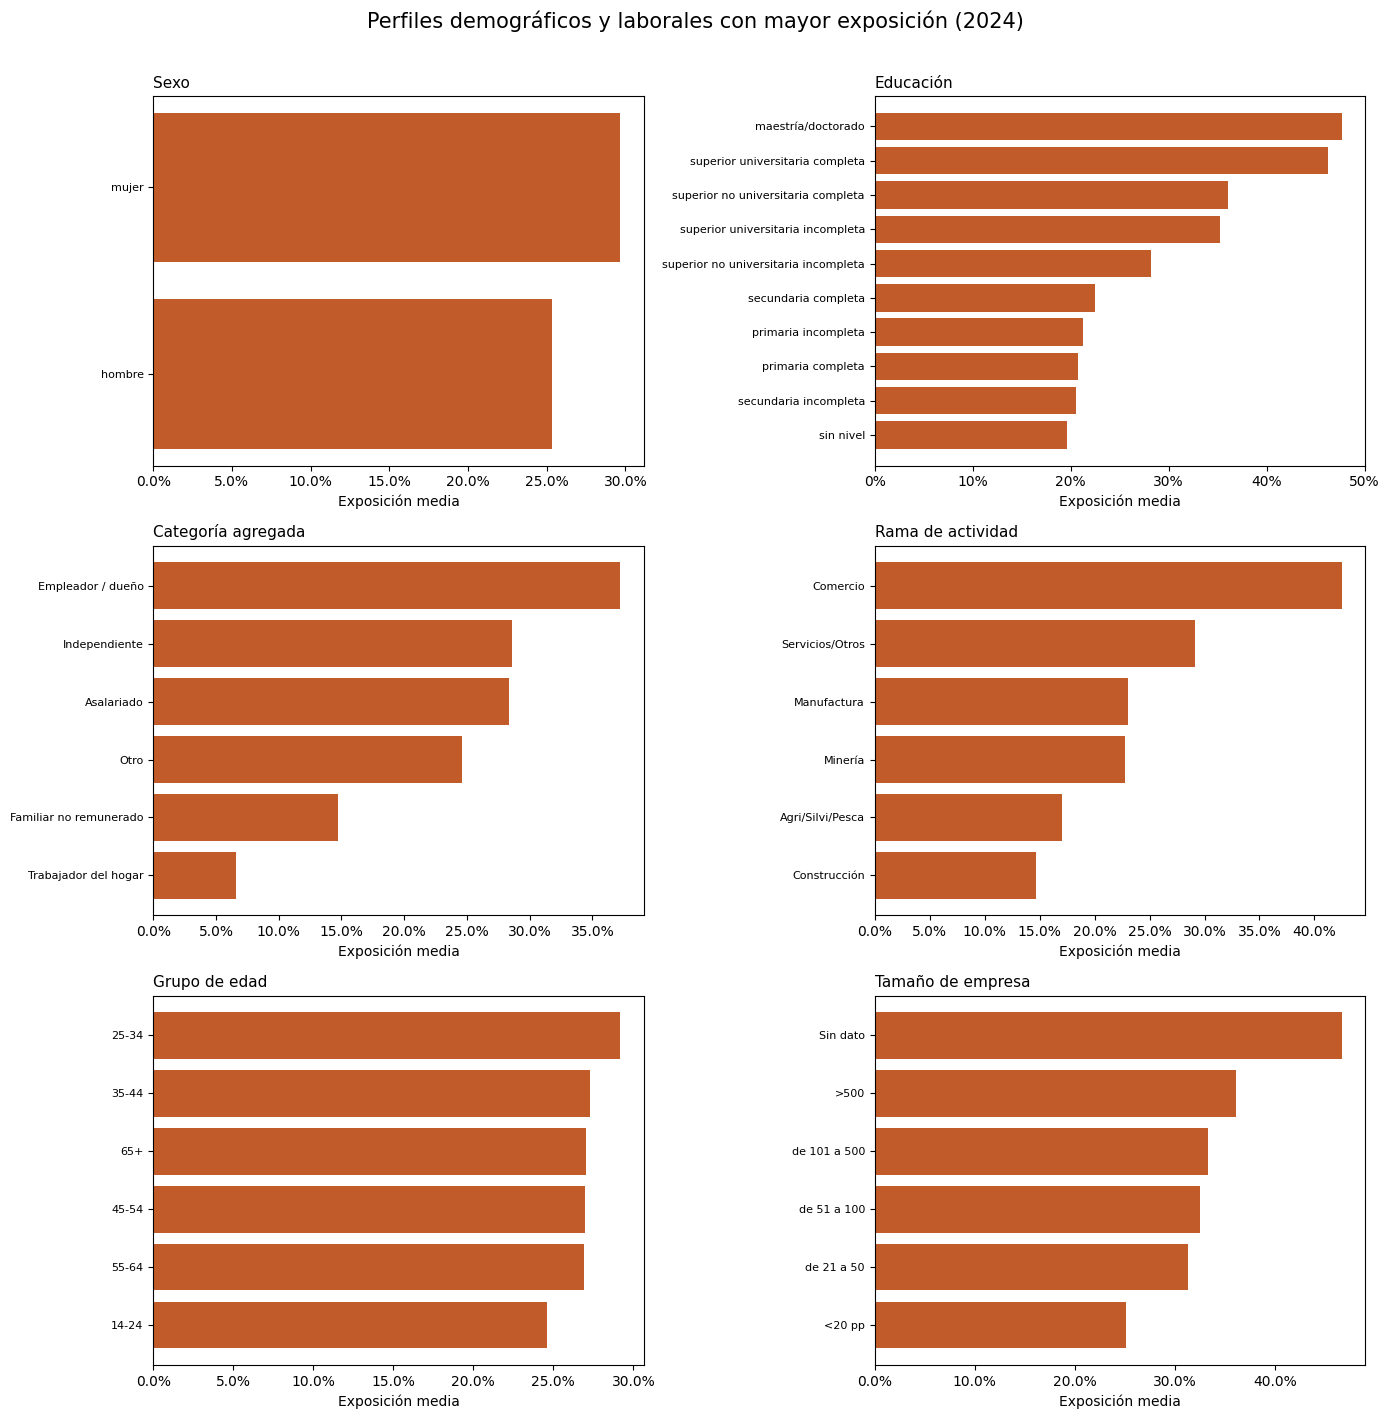

,Sexo,weighted_population,mean_exposure_score,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
1,mujer,7.651078e+06,0.296862,0.185814,0.008642,0.349762,0.433293
0,hombre,1.000688e+07,0.253452,0.121566,0.006298,0.257164,0.566707


,Educación,weighted_population,mean_exposure_score,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
9,maestría/doctorado,3.132735e+05,0.476750,0.307864,0.010982,0.711982,0.017766
3,superior universitaria completa,1.764743e+06,0.463006,0.332940,0.022406,0.653530,0.100078
2,superior no universitaria completa,1.842519e+06,0.360244,0.232298,0.018560,0.437132,0.104488
7,superior universitaria incompleta,1.019779e+06,0.352587,0.250152,0.018675,0.418327,0.057831
6,superior no universitaria incompleta,1.083940e+06,0.282416,0.169975,0.008455,0.314984,0.061470
0,secundaria completa,5.707942e+06,0.224922,0.108370,0.003447,0.212426,0.323694
5,primaria incompleta,1.604713e+06,0.212205,0.075510,0.000788,0.187459,0.091002
4,primaria completa,1.662420e+06,0.207129,0.069901,0.000362,0.178300,0.094275
1,secundaria incompleta,2.195241e+06,0.205480,0.089934,0.000952,0.187317,0.124491
8,sin nivel,4.391864e+05,0.196184,0.068757,0.000278,0.165981,0.024906


,Categoría ocupacional,weighted_population,mean_exposure_score,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
1,empleado,4.354976e+06,0.450773,0.306589,0.020203,0.605828,0.246630
4,empleador o patrono,6.111000e+05,0.372322,0.304584,0.055927,0.414323,0.034608
0,trabajador independiente,6.715431e+06,0.285646,0.143513,0.000996,0.294170,0.380306
6,otro,2.772056e+04,0.246233,0.187290,0.003635,0.330272,0.001570
3,trabajador familiar no remunerado,1.319556e+06,0.147032,0.081257,0.000033,0.150689,0.074729
2,obrero,4.220701e+06,0.111579,0.009641,0.000035,0.041263,0.239025
5,trabajador del hogar,4.084749e+05,0.065940,0.000000,0.000000,0.000657,0.023133


,Categoría agregada,weighted_population,mean_exposure_score,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
3,Empleador / dueño,6.111000e+05,0.372322,0.304584,0.055927,0.414323,0.034608
1,Independiente,6.715431e+06,0.285646,0.143513,0.000996,0.294170,0.380306
0,Asalariado,8.575677e+06,0.283831,0.160439,0.010277,0.327965,0.485655
5,Otro,2.772056e+04,0.246233,0.187290,0.003635,0.330272,0.001570
2,Familiar no remunerado,1.319556e+06,0.147032,0.081257,0.000033,0.150689,0.074729
4,Trabajador del hogar,4.084749e+05,0.065940,0.000000,0.000000,0.000657,0.023133


,Grupo de edad,weighted_population,mean_exposure_score,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
0,25-34,4.324610e+06,0.291974,0.173641,0.010574,0.337114,0.244910
1,35-44,3.960538e+06,0.272990,0.151601,0.007819,0.297164,0.224292
5,65+,1.249264e+06,0.270156,0.125861,0.004091,0.273946,0.070748
2,45-54,3.222172e+06,0.270016,0.138575,0.006865,0.288296,0.182477
4,55-64,2.157580e+06,0.269049,0.135390,0.005463,0.281474,0.122187
3,14-24,2.743797e+06,0.246262,0.142491,0.004895,0.268306,0.155386


,Contrato,weighted_population,mean_exposure_score,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
6,practicas preprof,7.639184e+04,0.421321,0.285822,0.011001,0.593769,0.004326
5,CAS,1.604882e+05,0.405764,0.231231,0.011199,0.550771,0.009089
7,periodo de prueba,3.315664e+04,0.402935,0.270338,0.020734,0.478439,0.001878
3,indefinido,1.205791e+06,0.402260,0.258147,0.022214,0.505379,0.068286
4,locacion de servicios,5.153664e+05,0.360953,0.213800,0.019217,0.456528,0.029186
2,plazo fijo,2.490105e+06,0.341790,0.212068,0.015095,0.413389,0.141019
8,otro,3.875031e+03,0.326811,0.199430,0.000000,0.443160,0.000219
0,Sin dato,7.329270e+06,0.292940,0.156998,0.005576,0.304307,0.415069
1,sin contrato,5.843516e+06,0.175657,0.080309,0.001827,0.170059,0.330928


,Tamaño de empresa,weighted_population,mean_exposure_score,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
5,Sin dato,2.738430e+03,0.466647,0.290049,0.000000,0.610050,0.000155
1,>500,2.283601e+06,0.361111,0.209946,0.016406,0.446942,0.129324
3,de 101 a 500,5.633989e+05,0.333324,0.202955,0.016769,0.396789,0.031906
4,de 51 a 100,4.222805e+05,0.325307,0.225875,0.014590,0.375969,0.023914
2,de 21 a 50,6.628405e+05,0.313434,0.181681,0.015204,0.366884,0.037538
0,<20 pp,1.372310e+07,0.251310,0.133191,0.004809,0.262452,0.777162


,Rama de actividad,weighted_population,mean_exposure_score,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
2,Comercio,3.431715e+06,0.424958,0.314719,0.005850,0.579498,0.194344
0,Servicios/Otros,7.028495e+06,0.291328,0.177014,0.012774,0.321216,0.398035
3,Manufactura,1.538725e+06,0.230321,0.094924,0.008040,0.217217,0.087141
5,Minería,2.238735e+05,0.227875,0.097693,0.006616,0.225033,0.012678
1,Agri/Silvi/Pesca,4.178236e+06,0.170429,0.019184,0.000322,0.110868,0.236621
4,Construcción,1.256915e+06,0.146504,0.052448,0.003249,0.123535,0.071181


,Estrato,weighted_population,mean_exposure_score,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
0,1,6.668687e+06,0.314151,0.197379,0.010722,0.367430,0.377659
2,2,2.547507e+06,0.292763,0.176996,0.009057,0.338380,0.144270
5,3,8.246492e+05,0.276340,0.161965,0.008180,0.309454,0.046701
4,4,1.372117e+06,0.261398,0.146017,0.005820,0.287714,0.077705
1,5,2.611620e+06,0.256985,0.130787,0.005545,0.271580,0.147900
7,6,5.120010e+05,0.227444,0.090148,0.002422,0.219806,0.028995
3,7,2.303130e+06,0.190058,0.049400,0.001540,0.149931,0.130430
6,8,8.182496e+05,0.189323,0.043519,0.000694,0.146752,0.046339


In [6]:
SHEET_LABELS = {
    "sexo": "Sexo",
    "educacion": "Educación",
    "categoria": "Categoría ocupacional",
    "categoria_agregada": "Categoría agregada",
    "grupo_edad": "Grupo de edad",
    "formalidad_contrato": "Contrato",
    "formalidad_tamano": "Tamaño de empresa",
    "rama": "Rama de actividad",
    "estrato": "Estrato",
}

primary_sheets = ["sexo", "educacion", "categoria_agregada", "rama", "grupo_edad", "formalidad_tamano"]
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for ax, sheet_name in zip(axes, primary_sheets):
    df = profiles[sheet_name].sort_values("mean_exposure_score", ascending=True).copy()
    ax.barh(df["group"], df["mean_exposure_score"], color=COLORS["accent"])
    ax.set_title(SHEET_LABELS[sheet_name], fontsize=11, loc="left")
    ax.set_xlabel("Exposición media")
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.tick_params(axis="y", labelsize=8)

for ax in axes[len(primary_sheets):]:
    ax.axis("off")

fig.suptitle(f"Perfiles demográficos y laborales con mayor exposición ({ANALYSIS_YEAR})", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

for sheet_name in PROFILE_SHEETS:
    display(
        profiles[sheet_name]
        .sort_values("mean_exposure_score", ascending=False)
        .rename(columns={"group": SHEET_LABELS.get(sheet_name, sheet_name.lower())})
    )

## 4. Extremos de exposición dentro de cada dimensión

In [7]:
comparison_df["dimension_label"] = comparison_df["dimension"].map(SHEET_LABELS).fillna(comparison_df["dimension"])
comparison_view = comparison_df[
    [
        "dimension_label",
        "top_group",
        "top_exposure",
        "bottom_group",
        "bottom_exposure",
        "gap_exposure",
    ]
].rename(
    columns={
        "dimension_label": "dimension",
        "top_group": "mayor_exposicion",
        "top_exposure": "score_mayor",
        "bottom_group": "menor_exposicion",
        "bottom_exposure": "score_menor",
        "gap_exposure": "brecha",
    }
)
display(comparison_view)

if HAS_PLOTLY:
    fig = px.bar(
        comparison_df.sort_values("gap_exposure"),
        x="gap_exposure",
        y="dimension_label",
        orientation="h",
        color="gap_exposure",
        color_continuous_scale=["#93c5fd", "#c25b2a"],
        custom_data=["top_group", "bottom_group", "top_exposure", "bottom_exposure"],
        labels={"gap_exposure": "Brecha de exposición", "dimension_label": "Dimensión"},
    )
    fig.update_traces(
        hovertemplate="<b>%{y}</b><br>Mayor exposición: %{customdata[0]} (%{customdata[2]:.1%})<br>"
        "Menor exposición: %{customdata[1]} (%{customdata[3]:.1%})<br>"
        "Brecha: %{x:.1%}<extra></extra>"
    )
    fig.update_layout(title=f"Mayor brecha interna de exposición por dimensión ({ANALYSIS_YEAR})", height=520)
    show_plotly(fig)
else:
    ordered = comparison_df.sort_values("gap_exposure")
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(ordered["dimension_label"], ordered["gap_exposure"], color=COLORS["accent2"])
    ax.set_xlabel("Brecha de exposición")
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_ylabel("")
    ax.set_title(f"Mayor brecha interna de exposición por dimensión ({ANALYSIS_YEAR})")
    plt.tight_layout()
    plt.show()

top_gap = comparison_df.iloc[0]
render_note(
    f"La mayor brecha interna del año aparece en <strong>{top_gap['dimension_label']}</strong>: "
    f"{top_gap['top_group']} alcanza {fmt_pct(top_gap['top_exposure'])} frente a {fmt_pct(top_gap['bottom_exposure'])} en {top_gap['bottom_group']}.",
    tone="blue",
)

,dimension,mayor_exposicion,score_mayor,menor_exposicion,score_menor,brecha
0,Categoría ocupacional,empleado,0.450773,trabajador del hogar,0.065940,0.384833
1,Categoría agregada,Empleador / dueño,0.372322,Trabajador del hogar,0.065940,0.306382
2,Educación,maestría/doctorado,0.476750,sin nivel,0.196184,0.280566
3,Rama de actividad,Comercio,0.424958,Construcción,0.146504,0.278454
4,Contrato,practicas preprof,0.421321,sin contrato,0.175657,0.245664
5,Tamaño de empresa,Sin dato,0.466647,<20 pp,0.251310,0.215337
6,Estrato,1.0,0.314151,8.0,0.189323,0.124828
7,Grupo de edad,25-34,0.291974,14-24,0.246262,0.045712
8,Sexo,mujer,0.296862,hombre,0.253452,0.043410


## 5. Ingresos y exposición

In [8]:
render_cards(
    [
        {
            "label": "Correlación ingreso-exposición",
            "value": f"{income_corr:.2f}" if pd.notna(income_corr) else "N/D",
            "sub": "Correlación entre ingreso mensual medio y score ocupacional",
        },
        {
            "label": "Ocupaciones en scatter",
            "value": fmt_num(len(income_df)),
            "sub": "Solo ocupaciones ENAHO con más de 50 mil ocupados e ingreso reportado",
        },
        {
            "label": "Ingreso medio máximo",
            "value": fmt_sol(income_df['income_monthly_weighted_mean'].max()),
            "sub": "Máximo ingreso promedio ocupacional del corte anual",
        },
    ]
)

if HAS_PLOTLY:
    fig = px.scatter(
        income_df,
        x="mean_exposure_score",
        y="income_monthly_weighted_mean",
        size="weighted_population",
        color="women_share_weighted",
        color_continuous_scale=["#2563eb", "#f59e0b", "#c25b2a"],
        hover_name="occupation_name_cno",
        hover_data={
            "occupation_code_4d": True,
            "income_monthly_weighted_mean": ":,.0f",
            "income_monthly_median_weighted": ":,.0f",
            "weighted_population": ":,.0f",
            "women_share_weighted": ":.1%",
        },
        labels={
            "mean_exposure_score": "Exposición media",
            "income_monthly_weighted_mean": "Ingreso mensual medio",
            "women_share_weighted": "Proporción de mujeres",
        },
        size_max=44,
    )
    fig.update_layout(
        title=f"Ingreso laboral mensual y exposición a IA ({ANALYSIS_YEAR})",
        height=620,
        margin=dict(l=10, r=10, t=60, b=20),
    )
    show_plotly(fig)
else:
    fig, ax = plt.subplots(figsize=(10, 7))
    sizes = np.sqrt(income_df["weighted_population"] / income_df["weighted_population"].max()) * 1400
    scatter = ax.scatter(
        income_df["mean_exposure_score"],
        income_df["income_monthly_weighted_mean"],
        s=sizes,
        c=income_df["women_share_weighted"],
        cmap="plasma",
        alpha=0.75,
        edgecolors="white",
        linewidth=0.6,
    )
    ax.set_xlabel("Exposición media")
    ax.set_ylabel("Ingreso mensual medio")
    ax.yaxis.set_major_formatter(StrMethodFormatter("S/ {x:,.0f}"))
    ax.set_title(f"Ingreso laboral mensual y exposición a IA ({ANALYSIS_YEAR})")
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label("Proporción de mujeres")
    plt.tight_layout()
    plt.show()

display(
    income_df[
        [
            "occupation_code_4d",
            "occupation_name_cno",
            "weighted_population",
            "income_monthly_weighted_mean",
            "income_monthly_median_weighted",
            "mean_exposure_score",
        ]
    ]
    .sort_values(["mean_exposure_score", "income_monthly_weighted_mean"], ascending=[False, False])
    .head(20)
)

render_note(
    f"Chequeo de ingresos extremos en microdatos armonizados del año: {outliers_over_20k} casos por encima de S/ 20 mil y {outliers_over_50k} por encima de S/ 50 mil.",
    tone="green",
)

,occupation_code_4d,occupation_name_cno,weighted_population,income_monthly_weighted_mean,income_monthly_median_weighted,mean_exposure_score
17,4312,"Empleados de servicios estadísticos, financier...",5.796697e+04,2622.603474,2215.0,0.7775
16,4222,Empleados de centros de llamadas,7.759956e+04,1243.761408,1100.0,0.7025
28,5243,Vendedores por teléfono,5.646361e+04,1215.720527,1103.0,0.6808
12,3314,Técnicos en administración,2.601597e+05,2350.638113,1800.0,0.6725
7,2411,Contadores,8.726444e+04,3060.336877,2680.0,0.6713
14,4110,Jefes de empleados administrativos,1.550957e+05,4074.932741,3040.0,0.6333
19,4417,"Auxiliares en la administración, contabilidad,...",6.074048e+04,1660.823582,1400.0,0.6007
25,5212,Vendedores minoristas en tiendas y establecimi...,1.326993e+06,1101.908136,1025.0,0.5993
6,2359,Otros profesionales de la enseñanza,7.354687e+04,1593.212439,1235.0,0.5800
15,4120,Secretarios,6.679462e+04,1588.515917,1500.0,0.5467


## 6. Perfiles del trabajador expuesto

In [9]:
def weighted_mode(series, weights):
    valid = pd.DataFrame({"value": series, "weight": weights}).dropna()
    if valid.empty:
        return "N/D"
    return valid.groupby("value")["weight"].sum().sort_values(ascending=False).index[0]

def build_persona(df, label, tier):
    if df.empty:
        return None
    weights = df["weight"]
    total = weights.sum()
    occ_top = (
        df.groupby(["occupation_code_4d", "occupation_group"], dropna=False)["weight"]
        .sum()
        .sort_values(ascending=False)
        .head(3)
    )
    top_occupations = [
        {
            "code": code,
            "name": str(name)[:62] if pd.notna(name) else "N/D",
            "workers": float(workers),
        }
        for (code, name), workers in occ_top.items()
    ]
    income_valid = df[df["labor_income_monthly"].notna()].copy()
    return {
        "label": label,
        "tier": tier,
        "total_workers": float(total),
        "mean_exposure": weighted_mean(df["mean_exposure_score"], weights),
        "pct_aumento": weighted_mean(df["%_aumento"], weights),
        "pct_sustitucion": weighted_mean(df["%_sustitucion"], weights),
        "pct_women": weighted_share(df["sex"].astype(str).eq("Mujer"), weights),
        "pct_urban": weighted_mean(df["is_urban"], weights),
        "mean_age": weighted_mean(df["age"], weights),
        "income_mean": weighted_mean(income_valid["labor_income_monthly"], income_valid["weight"]),
        "top_category": weighted_mode(df["category_label"], weights),
        "top_education": weighted_mode(df["education_label"], weights),
        "top_occupations": top_occupations,
    }

persona_records = [
    build_persona(persona_q4, f"Perú {ANALYSIS_YEAR} — alta exposición (Q4)", "alta"),
    build_persona(persona_q1, f"Perú {ANALYSIS_YEAR} — baja exposición (Q1)", "baja"),
]

for region_code, region_name in PERSONA_REGIONS:
    sub = enaho_micro[pd.to_numeric(enaho_micro["region_code"], errors="coerce") == region_code].copy()
    if len(sub) < 40:
        continue
    q75_region = sub["mean_exposure_score"].quantile(0.75)
    persona_records.append(
        build_persona(sub[sub["mean_exposure_score"] >= q75_region], f"{region_name} {ANALYSIS_YEAR} — alta exposición (Q4)", "alta")
    )

persona_records = [p for p in persona_records if p is not None]
persona_export = pd.DataFrame(
    [
        {
            k: json.dumps(v, ensure_ascii=False) if isinstance(v, list) else v
            for k, v in persona.items()
        }
        for persona in persona_records
    ]
)

cards = []
for persona in persona_records:
    occ_html = "".join(
        [
            f"<li><span class='mini-tag'>{o['code']}</span>{o['name']} ({fmt_num(o['workers'])})</li>"
            for o in persona["top_occupations"]
        ]
    )
    cards.append(
        f'''
        <div class="audit-card">
          <div class="eyebrow">{persona['label']}</div>
          <div class="value">{fmt_pct(persona['mean_exposure'])}</div>
          <div class="sub">{persona['top_category']} · {persona['top_education']}</div>
          <div style="margin-top:10px;font-size:12px;color:{COLORS['muted']};">
            Mujeres: {fmt_pct(persona['pct_women'])} · Urbano: {fmt_pct(persona['pct_urban'])} · Edad media: {persona['mean_age']:.1f}
          </div>
          <div style="margin-top:6px;font-size:12px;color:{COLORS['muted']};">
            Ingreso mensual: {fmt_sol(persona['income_mean'])} · Augmentation: {fmt_pct(persona['pct_aumento'])}
          </div>
          <ul style="margin:10px 0 0 18px;padding:0;font-size:12px;color:{COLORS['text']};">{occ_html}</ul>
        </div>
        '''
    )
display(HTML("<div class='audit-grid'>" + "".join(cards) + "</div>"))

persona_compare = pd.DataFrame(
    [
        {"metric": "Mujeres", "Q4": persona_records[0]["pct_women"], "Q1": persona_records[1]["pct_women"]},
        {"metric": "Urbano", "Q4": persona_records[0]["pct_urban"], "Q1": persona_records[1]["pct_urban"]},
        {"metric": "Augmentation", "Q4": persona_records[0]["pct_aumento"], "Q1": persona_records[1]["pct_aumento"]},
        {"metric": "Sustitución", "Q4": persona_records[0]["pct_sustitucion"], "Q1": persona_records[1]["pct_sustitucion"]},
    ]
)

if HAS_PLOTLY:
    fig = go.Figure()
    fig.add_bar(name="Q4 alta exposición", x=persona_compare["metric"], y=persona_compare["Q4"], marker_color=COLORS["accent"])
    fig.add_bar(name="Q1 baja exposición", x=persona_compare["metric"], y=persona_compare["Q1"], marker_color=COLORS["accent2"])
    fig.update_layout(
        title=f"Comparación de perfiles del trabajador expuesto ({ANALYSIS_YEAR})",
        barmode="group",
        yaxis_tickformat=".0%",
        height=460,
    )
    show_plotly(fig)
else:
    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(persona_compare))
    width = 0.35
    ax.bar(x - width / 2, persona_compare["Q4"], width, label="Q4 alta exposición", color=COLORS["accent"])
    ax.bar(x + width / 2, persona_compare["Q1"], width, label="Q1 baja exposición", color=COLORS["accent2"])
    ax.set_xticks(x)
    ax.set_xticklabels(persona_compare["metric"])
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(f"Comparación de perfiles del trabajador expuesto ({ANALYSIS_YEAR})")
    ax.legend()
    plt.tight_layout()
    plt.show()

persona_export

,label,tier,total_workers,mean_exposure,pct_aumento,pct_sustitucion,pct_women,pct_urban,mean_age,income_mean,top_category,top_education,top_occupations
0,Perú 2024 — alta exposición (Q4),alta,5.044656e+06,0.534738,0.792574,0.025600,0.529387,0.937410,39.200313,2347.526788,Empleado/a,N/D,"[{""code"": ""5212"", ""name"": ""Vendedores minorist..."
1,Perú 2024 — baja exposición (Q1),baja,3.996676e+06,0.052066,0.000000,0.000000,0.460641,0.637941,37.668183,1108.163751,Obrero/a,N/D,"[{""code"": ""9211"", ""name"": ""Peones de explotaci..."
2,Lima 2024 — alta exposición (Q4),alta,1.484625e+06,0.593757,0.888983,0.039979,0.521530,0.995365,38.702741,2565.565491,Empleado/a,N/D,"[{""code"": ""5212"", ""name"": ""Vendedores minorist..."
3,Arequipa 2024 — alta exposición (Q4),alta,2.125871e+05,0.550979,0.848789,0.027055,0.513361,0.975486,39.821257,2284.738312,Empleado/a,N/D,"[{""code"": ""5212"", ""name"": ""Vendedores minorist..."
4,La Libertad 2024 — alta exposición (Q4),alta,2.491255e+05,0.543397,0.834009,0.021028,0.515161,0.960832,38.849724,2001.013941,Empleado/a,N/D,"[{""code"": ""5212"", ""name"": ""Vendedores minorist..."
5,Callao 2024 — alta exposición (Q4),alta,1.330002e+05,0.602309,0.898808,0.045627,0.504803,1.000000,38.008991,2133.356375,Empleado/a,N/D,"[{""code"": ""5212"", ""name"": ""Vendedores minorist..."


## 7. Análisis departamental

In [10]:
if regional_df.empty:
    render_note(
        f"No hay corte EPEN anual disponible para {ANALYSIS_YEAR}. El bloque departamental solo puede replicarse desde 2022 en adelante.",
        tone="blue",
    )
else:
    render_cards(
        [
            {
                "label": "Departamentos con dato",
                "value": fmt_num(len(regional_df)),
                "sub": "EPEN anual con match ocupacional e ingreso mensual",
            },
            {
                "label": "Mayor exposición departamental",
                "value": fmt_pct(regional_df['mean_exposure'].max()),
                "sub": str(regional_df.iloc[0]["region_name"]),
            },
            {
                "label": "Ingreso departamental más alto",
                "value": fmt_sol(regional_df['income_mean'].max()),
                "sub": str(regional_df.sort_values('income_mean', ascending=False).iloc[0]["region_name"]),
            },
        ]
    )

    if HAS_PLOTLY:
        fig = px.bar(
            regional_df.sort_values("mean_exposure"),
            x="mean_exposure",
            y="region_name",
            orientation="h",
            color="income_mean",
            color_continuous_scale=["#bfdbfe", "#2563eb"],
            hover_data={"workers": ":,.0f", "pct_alta": ":.1%", "pct_aumento": ":.1%"},
            labels={"mean_exposure": "Exposición media", "region_name": "Departamento", "income_mean": "Ingreso medio"},
        )
        fig.update_layout(title=f"Exposición a IA por departamento ({ANALYSIS_YEAR})", height=700)
        show_plotly(fig)
    else:
        ordered = regional_df.sort_values("mean_exposure")
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.barh(ordered["region_name"], ordered["mean_exposure"], color=COLORS["accent2"])
        ax.xaxis.set_major_formatter(PercentFormatter(1.0))
        ax.set_title(f"Exposición a IA por departamento ({ANALYSIS_YEAR})")
        ax.set_xlabel("Exposición media")
        plt.tight_layout()
        plt.show()

    regional_occ_view = (
        regional_top_occ.sort_values(["region_code", "mean_exposure"], ascending=[True, False])
        .groupby("region_code")
        .head(3)
        .merge(regional_df[["region_code", "region_name"]], how="left", on="region_code")
    )
    display(
        regional_occ_view[
            ["region_name", "occupation_code_4d", "occupation_group", "workers", "mean_exposure"]
        ].rename(
            columns={
                "region_name": "departamento",
                "occupation_code_4d": "cno_4d",
                "occupation_group": "ocupacion",
                "workers": "trabajadores",
                "mean_exposure": "exposicion_media",
            }
        )
    )

,departamento,cno_4d,ocupacion,trabajadores,exposicion_media
0,Amazonas,6114,Agricultores y trabajadores calificados de cul...,46232.654644,0.2639
1,Amazonas,9211,Peones de explotaciones agrícolas y ganaderas,54231.727489,0.0500
2,Ancash,5212,Vendedores minoristas en tiendas y establecimi...,32927.888741,0.5993
3,Ancash,5223,Asistentes de venta en tiendas y almacenes,12626.283582,0.4500
4,Ancash,5120,Cocineros,14655.786882,0.3300
5,Apurímac,5212,Vendedores minoristas en tiendas y establecimi...,11749.245875,0.5993
6,Apurímac,6114,Agricultores y trabajadores calificados de cul...,62950.354442,0.2639
7,Apurímac,9211,Peones de explotaciones agrícolas y ganaderas,57458.786215,0.0500
8,Arequipa,3314,Técnicos en administración,16857.183629,0.6725
9,Arequipa,4417,"Auxiliares en la administración, contabilidad,...",15790.702989,0.6007


## 8. Auditoría anual de coherencia

In [11]:
calc_coverage = matched_base["factor"].sum() / base["factor"].sum()
calc_mean_exposure = weighted_mean(matched_base["mean_exposure_score"], matched_base["factor"])
calc_pct_alta = weighted_mean(matched_base["%_alta_exposicion"], matched_base["factor"])
calc_pct_aumento = weighted_mean(matched_base["%_aumento"], matched_base["factor"])
calc_pct_sustitucion = weighted_mean(matched_base["%_sustitucion"], matched_base["factor"])

audit_frame = pd.DataFrame(
    [
        {
            "analysis_year": ANALYSIS_YEAR,
            "coverage_report": coverage["cobertura_ponderada"],
            "coverage_rebuilt": calc_coverage,
            "coverage_diff": abs(calc_coverage - coverage["cobertura_ponderada"]),
            "mean_exposure_report": coverage["media_exposicion_ponderada"],
            "mean_exposure_rebuilt": calc_mean_exposure,
            "mean_exposure_diff": abs(calc_mean_exposure - coverage["media_exposicion_ponderada"]),
            "pct_alta_report": coverage["media_pct_alta_ponderada"],
            "pct_alta_rebuilt": calc_pct_alta,
            "pct_aumento_report": coverage["media_pct_aumento_ponderada"],
            "pct_aumento_rebuilt": calc_pct_aumento,
            "pct_sustitucion_report": coverage["media_pct_sustitucion_ponderada"],
            "pct_sustitucion_rebuilt": calc_pct_sustitucion,
            "unmatched_occupations": len(unmatched_occ),
            "outliers_over_20k": outliers_over_20k,
            "outliers_over_50k": outliers_over_50k,
        }
    ]
)

render_cards(
    [
        {
            "label": "Diferencia cobertura",
            "value": f"{audit_frame.iloc[0]['coverage_diff']:.6f}",
            "sub": "Reporte anual vs reconstrucción desde microdatos",
        },
        {
            "label": "Diferencia exposición media",
            "value": f"{audit_frame.iloc[0]['mean_exposure_diff']:.6f}",
            "sub": "Debe tender a cero si no hay contradicción interna",
        },
        {
            "label": "Ocupaciones fuera del índice",
            "value": fmt_num(len(unmatched_occ)),
            "sub": f"{fmt_num(unmatched_occ['weighted_population'].sum())} ocupados ponderados sin score",
        },
        {
            "label": "Atípicos de ingreso >50k",
            "value": fmt_num(outliers_over_50k),
            "sub": f"{fmt_num(outliers_over_20k)} casos por encima de 20k",
        },
    ]
)

if audit_frame.iloc[0]["coverage_diff"] < 1e-9 and audit_frame.iloc[0]["mean_exposure_diff"] < 1e-9:
    render_note("La reconstrucción desde microdatos replica exactamente los indicadores de cobertura y exposición media del reporte anual. No se detectaron contradicciones internas en estas métricas.", tone="green")
else:
    render_note("La auditoría encontró diferencias no triviales entre el reporte anual y la reconstrucción desde microdatos. Este caso requiere revisar el pipeline antes de usar resultados externos.", tone="amber")

display(
    unmatched_occ.head(15).rename(
        columns={
            "occupation_code_4d": "cno_4d",
            "weighted_population": "trabajadores",
            "occupation_name_cno": "ocupacion",
            "reason": "motivo",
        }
    )
)

audit_frame

,cno_4d,trabajadores,ocupacion,motivo
0,4419,305214.703951,Otro personal de apoyo administrativo,Sin score en índice IA
1,0220,73242.162605,Suboficiales de la Policía Nacional,Sin score en índice IA
2,7399,51048.721787,Otros Artesanos y trabajadores en la elaboraci...,Sin score en índice IA
3,3439,43796.206674,Otros profesionales técnicos en actividades cu...,Sin score en índice IA
4,7129,27750.422290,Otros pintores excepto brocha gorda,Sin score en índice IA
5,7519,15699.928194,Otros trabajadores de la preparación de alimen...,Sin score en índice IA
6,8189,10523.921866,Otros Operadores de máquinas y de instalacione...,Sin score en índice IA
7,3149,9056.202560,Otros técnicos en control de procesos,Sin score en índice IA
8,0312,8462.905457,Técnicos de la Marina de Guerra,Sin score en índice IA
9,3129,8222.125895,"Otros supervisores en ingeniería de minas, de ...",Sin score en índice IA


,analysis_year,coverage_report,coverage_rebuilt,coverage_diff,mean_exposure_report,mean_exposure_rebuilt,mean_exposure_diff,pct_alta_report,pct_alta_rebuilt,pct_aumento_report,pct_aumento_rebuilt,pct_sustitucion_report,pct_sustitucion_rebuilt,unmatched_occupations,outliers_over_20k,outliers_over_50k
0,2024,0.968657,0.968657,0.0,0.272261,0.272261,5.551115e-17,0.149404,0.149404,0.297286,0.297286,0.007314,0.007314,22,3,0


## 9. Exportación de tablas auxiliares

In [12]:
export_map = {
    f"coverage_{ANALYSIS_YEAR}.csv": pd.DataFrame([coverage]),
    f"occupation_summary_{ANALYSIS_YEAR}.csv": occupation_summary,
    f"top_occupations_{ANALYSIS_YEAR}.csv": top_occ,
    f"bubble_occupations_{ANALYSIS_YEAR}.csv": bubble_df,
    f"comparison_{ANALYSIS_YEAR}.csv": comparison_df,
    f"income_scatter_{ANALYSIS_YEAR}.csv": income_df,
    f"personas_{ANALYSIS_YEAR}.csv": persona_export,
    f"regional_{ANALYSIS_YEAR}.csv": regional_df,
    f"regional_top_occ_{ANALYSIS_YEAR}.csv": regional_top_occ,
    f"unmatched_occupations_{ANALYSIS_YEAR}.csv": unmatched_occ,
    f"audit_{ANALYSIS_YEAR}.csv": audit_frame,
}

for sheet_name, df in profiles.items():
    export_map[f"profile_{sheet_name}_{ANALYSIS_YEAR}.csv"] = df

for filename, df in export_map.items():
    df.to_csv(OUTPUT_TABLES / filename, index=False)

with (OUTPUT_TABLES / f"audit_summary_{ANALYSIS_YEAR}.json").open("w", encoding="utf-8") as fh:
    json.dump(audit_summary, fh, ensure_ascii=False, indent=2)

exported_files = sorted(p.name for p in OUTPUT_TABLES.iterdir())
print(f"Tablas exportadas en: {OUTPUT_TABLES}")
pd.DataFrame({"archivo": exported_files})

Tablas exportadas en: C:\Users\VALENTINALINARES\OneDrive - Universidad del Pacífico\Desktop\up cowork\ENAHO 2026\Proyecto_IA_Empleo_2026\outputs\enaho_exposure_2024\annual_tables


,archivo
0,audit_2024.csv
1,audit_summary_2024.json
2,bubble_occupations_2024.csv
3,comparison_2024.csv
4,coverage_2024.csv
5,income_scatter_2024.csv
6,occupation_summary_2024.csv
7,personas_2024.csv
8,profile_categoria_2024.csv
9,profile_categoria_agregada_2024.csv
